# Glassdoor Tech Salary Prediction — EDA & Modeling
Glassdoor job postings (2017–2018). Goals: how salary varies by **role**, **company size** and **location**, and whether we can **predict** salary from job attributes.

All cleaning and plotting code lives in `src/` so the notebook, the Streamlit app and the tests share one implementation. Salaries are in **$K per year**.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
os.chdir('..')
%matplotlib inline
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data_preprocessing import load_and_clean, clean_data, FEATURES, TARGET, SIZES
from src.eda import PLOTS

## 1. Raw data

In [2]:
raw = pd.read_csv('data/glassdoor_jobs.csv')
print(raw.shape)
raw[['Job Title','Salary Estimate','Rating','Location','Size','Founded']].head()

(956, 15)


,Job Title,Salary Estimate,Rating,Location,Size,Founded
0,Data Scientist,$53K-$91K (Glassdoor est.),3.8,"Albuquerque, NM",501 to 1000 employees,1973
1,Healthcare Data Scientist,$63K-$112K (Glassdoor est.),3.4,"Linthicum, MD",10000+ employees,1984
2,Data Scientist,$80K-$90K (Glassdoor est.),4.8,"Clearwater, FL",501 to 1000 employees,2010
3,Data Scientist,$56K-$97K (Glassdoor est.),3.8,"Richland, WA",1001 to 5000 employees,1965
4,Data Scientist,$86K-$143K (Glassdoor est.),2.9,"New York, NY",51 to 200 employees,1998


In [3]:
print('Rows with missing salary (-1):', (raw['Salary Estimate'] == '-1').sum())
print('Hourly / employer-provided rows:', raw['Salary Estimate'].str.contains('Per Hour|Employer').sum())
print('Missing rating (-1):', (raw['Rating'] <= 0).sum(), '| missing founded (-1):', (raw['Founded'] <= 0).sum())

Rows with missing salary (-1): 214
Hourly / employer-provided rows: 50
Missing rating (-1): 34 | missing founded (-1): 97


## 2. Cleaning
- `Salary Estimate` text → min/max/avg in $K (hourly × 2080 h). The raw marker `-1` is treated as missing.
- Job title → role bucket by keyword rules. Rows with unknown company size are dropped; missing rating/age are median-filled.
- State kept for the 7 most common states, others grouped as `Other`.

In [4]:
df = load_and_clean('data/glassdoor_jobs.csv')
print(raw.shape, '->', df.shape)
df['Job_Role'].value_counts()

(956, 15) -> (732, 9)


Job_Role
Data Scientist       298
Other Role           137
Software Engineer    130
Data Analyst         126
ML Engineer           37
DevOps Engineer        4
Name: count, dtype: int64

> **Caveat:** most postings in this dataset come from "data scientist" searches. The `Other Role` bucket is dominated by lab/research scientists, and `DevOps Engineer` has only 4 rows, so no conclusions are drawn about DevOps.

## 3. Exploratory analysis

### 3.1 Salary distribution

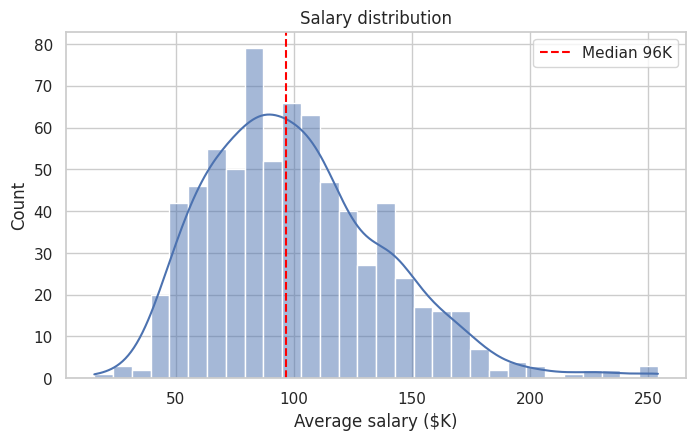

In [5]:
fig = PLOTS['Salary distribution'](df); plt.show()

### 3.2 By job role

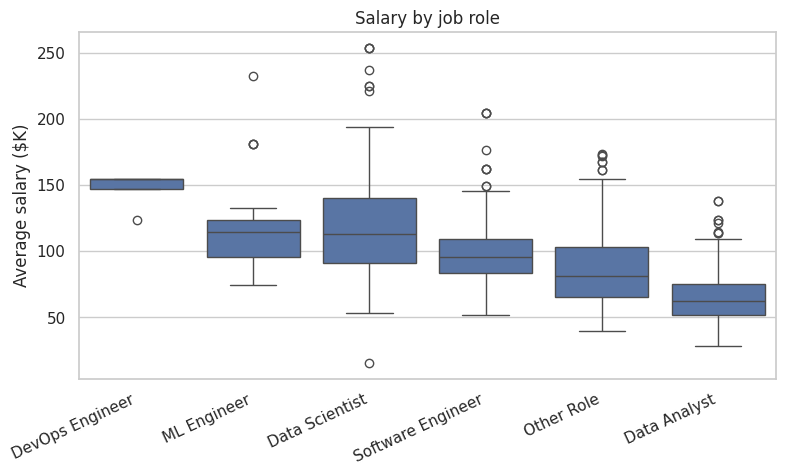

In [6]:
fig = PLOTS['By job role'](df); plt.show()

### 3.3 By company size

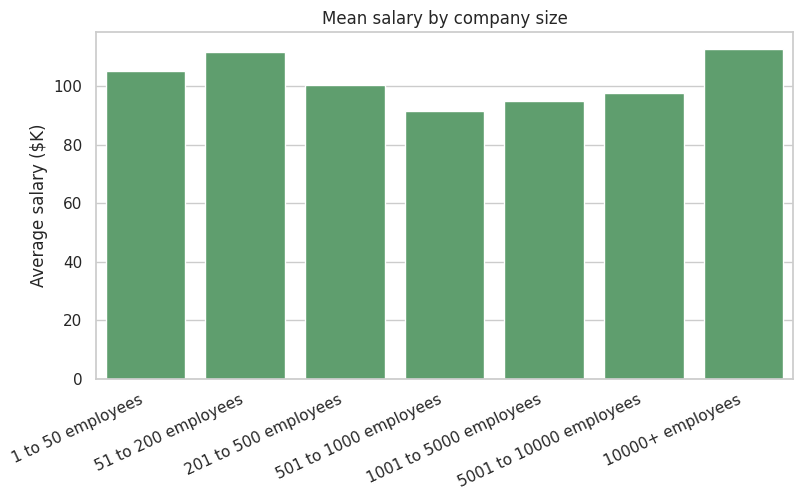

In [7]:
fig = PLOTS['By company size'](df); plt.show()

### 3.4 By state

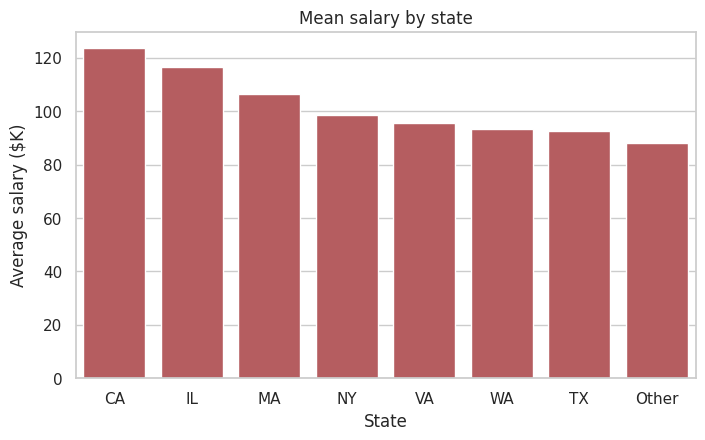

In [8]:
fig = PLOTS['By state'](df); plt.show()

### 3.5 By city

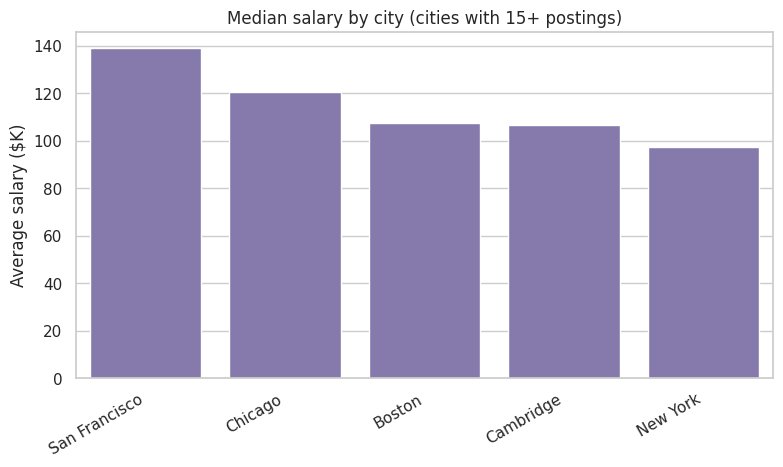

In [9]:
fig = PLOTS['By city'](df); plt.show()

### 3.6 Rating vs salary

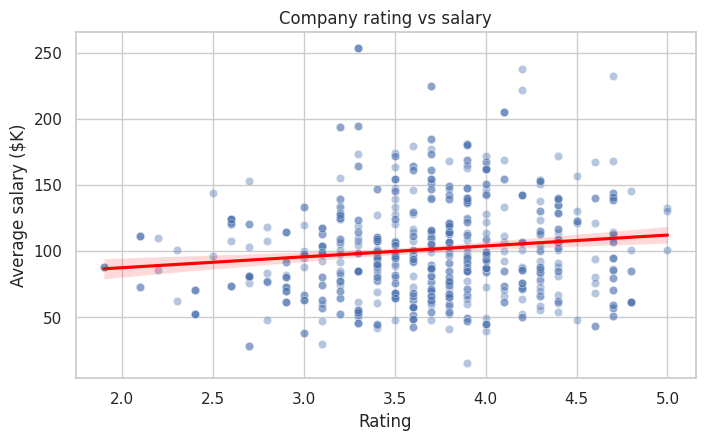

In [10]:
fig = PLOTS['Rating vs salary'](df); plt.show()

### 3.7 Company age vs salary

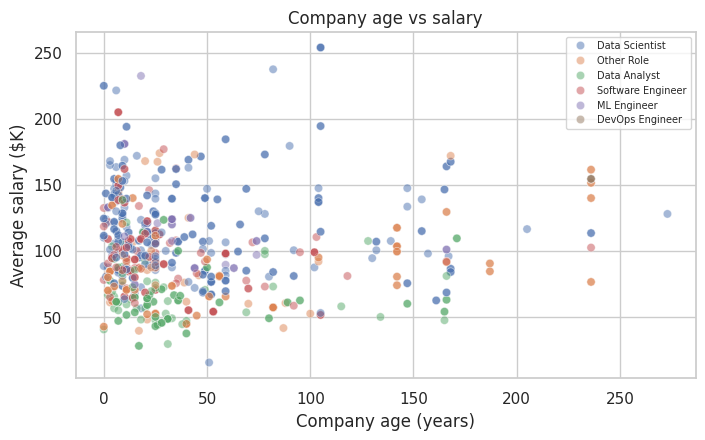

In [11]:
fig = PLOTS['Company age vs salary'](df); plt.show()

### 3.8 Correlation heatmap

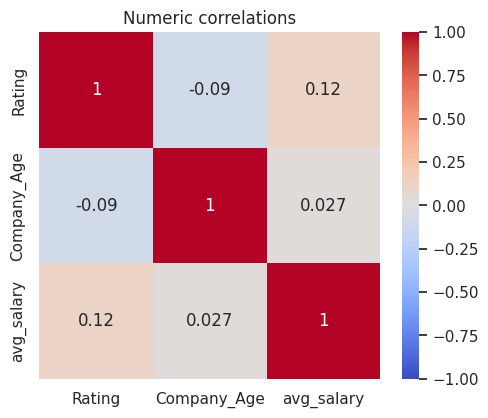

In [12]:
fig = PLOTS['Correlation heatmap'](df); plt.show()

### 3.9 Summary tables

In [13]:
pd.concat({
  'role':  df.groupby('Job_Role')[TARGET].agg(['count','median']),
  'size':  df.groupby('Size')[TARGET].agg(['count','median']).reindex(SIZES),
  'state': df.groupby('State')[TARGET].agg(['count','median']).sort_values('median', ascending=False),
}, axis=0).round(1)

count  median
role  Data Analyst               126    62.5
      Data Scientist             298   113.5
      DevOps Engineer              4   154.5
      ML Engineer                 37   114.5
      Other Role                 137    81.5
      Software Engineer          130    95.5
size  1 to 50 employees           31   109.0
      51 to 200 employees         94   111.0
      201 to 500 employees       117    96.0
      501 to 1000 employees      134    86.8
      1001 to 5000 employees     150    91.2
      5001 to 10000 employees     76    98.5
      10000+ employees           130   106.5
state CA                         152   120.8
      IL                          40   107.5
      MA                          96   104.5
      TX                          28    90.2
      VA                          41    89.5
      NY                          71    87.5
      Other                      283    86.0
      WA                          21    80.5

In [14]:
cc = df['City'].value_counts()
city = (df[df.City.isin(['San Francisco','Austin','New York'])]
        .groupby('City')[TARGET].agg(['count','median']).round(1))
city  # Austin has too few postings to trust

,count,median
City,,
Austin,8,122.0
New York,54,97.5
San Francisco,49,139.0


## 4. Modeling
Hold-out metrics come from one 80/20 split; **5-fold CV is the number to trust** with only ~730 rows.

In [15]:
from sklearn.model_selection import cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from src.data_preprocessing import CAT_FEATURES, NUM_FEATURES
from src.train_model import build_pipeline

X, y = df[FEATURES], df[TARGET]
ridge = make_pipeline(ColumnTransformer([('c', OneHotEncoder(handle_unknown='ignore'), CAT_FEATURES),
                                         ('n', 'passthrough', NUM_FEATURES)]), Ridge())
models = {'Mean baseline': DummyRegressor(), 'Ridge': ridge, 'Random Forest': build_pipeline()}
rows = []
for name, m in models.items():
    r2 = cross_val_score(m, X, y, cv=5, scoring='r2')
    mae = -cross_val_score(m, X, y, cv=5, scoring='neg_mean_absolute_error')
    rows.append((name, r2.mean(), mae.mean()))
pd.DataFrame(rows, columns=['model','CV R²','CV MAE ($K)']).round(2)

,model,CV R²,CV MAE ($K)
0,Mean baseline,-0.00,29.57
1,Ridge,0.35,23.04
2,Random Forest,0.53,17.70


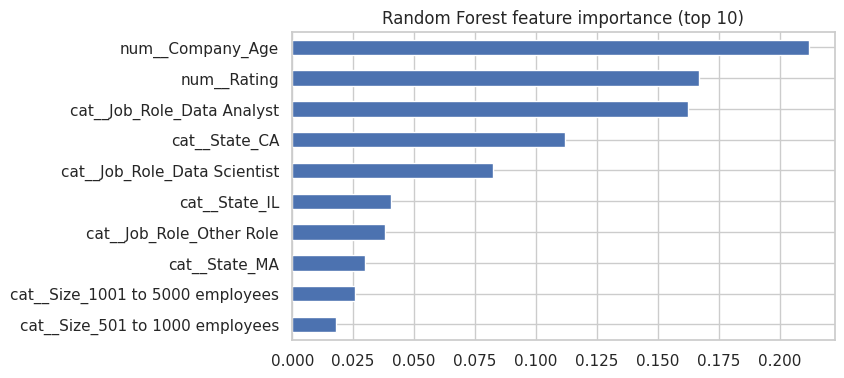

In [16]:
rf = build_pipeline().fit(X, y)
imp = pd.Series(rf[-1].feature_importances_, index=rf[:-1].get_feature_names_out()).sort_values()
imp.tail(10).plot.barh(figsize=(7,4), title='Random Forest feature importance (top 10)'); plt.show()

In [17]:
from src.predict import predict_with_interval
row = dict(Job_Role='Data Scientist', Size=SIZES[3], Rating=4.0, State='CA', Company_Age=20)
print('mean, P10, P90 ($K):', [round(v,1) for v in predict_with_interval(rf, row)])

mean, P10, P90 ($K): [136.7, 103.5, 181.5]


## 5. Findings

**Role.** Data Scientist (median ≈ $114K) and ML Engineer (≈ $115K, n=37) are paid far more than Data Analyst (≈ $63K) and Software Engineer (≈ $96K) in this sample. The role is the clearest salary signal.

**Company size.** No clean "bigger pays more" trend. The smallest companies (≤200 employees, ≈ $109–111K) and the largest (10,000+, ≈ $107K) have the highest medians; 501–1000 employees is lowest (≈ $87K). The role mix within each size bucket probably explains part of this, which this notebook does not control for.

**Location.** California has the highest state median (≈ $121K); Washington the lowest of the listed states (≈ $81K, n=21). By city: San Francisco ≈ $139K (n=49), Chicago ≈ $121K, Boston ≈ $108K, Cambridge ≈ $107K, New York ≈ $98K (n=54). Austin has only 8 postings, so it cannot be compared reliably. Differences between cities may partly reflect which roles were posted there.

**Rating and company age.** Both correlate only weakly with salary (r ≈ 0.12 and 0.03).

**Model.** A Random Forest reaches CV R² ≈ 0.53 and MAE ≈ $17.7K, versus R² ≈ 0 / MAE ≈ $29.6K for predicting the mean and R² ≈ 0.35 for Ridge. It is a useful estimator, not a precise one. Impurity importance ranks company age and rating high, but that metric favours continuous features and their linear correlation with salary is weak, so do not read it as causal.

## 6. Limitations
- Only ~730 usable postings, mostly data-science searches, from 2017–2018.
- Salaries are Glassdoor *estimates* (midpoint of a range), not actual pay.
- No experience, skills or seniority features, which usually matter a lot.
- The dataset is not a random sample of the tech job market.